# 4) Ligand Composition Analysis

In [1]:
import os
import sys
import scope

sys.path.insert(0, os.path.abspath('..'))
from local_functions import *

import matplotlib.pyplot as plt

## 1. User Configuration

In [2]:
data_path     = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/"                                                          # Update with your path
analysis_path = "/Users/sergivela/Documents/SCOPE/ATLAS/Analyses/1-TMC_Thermodynamics/"                  # Update with your path
env_path      = "/Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy"                                       # Update with your path
figures_path  = "/Users/sergivela/Documents/SCOPE/ATLAS/Analyses/1-TMC_Thermodynamics/Figures/"          # Update with your path
save_figures  = True

if not save_figures:
    figures_path = None

# Normalizes the configured strings and defines the analysis output folders.
data_path        = os.path.abspath(os.path.expanduser(data_path)) + os.sep
env_path         = os.path.abspath(os.path.expanduser(env_path))
analysis_path    = os.path.abspath(os.path.expanduser(analysis_path)) + os.sep
outputs_path     = analysis_path + "Outputs/"
html_figures_path = os.path.join(figures_path, "HTML") if figures_path else None

# Checks SCOPE version
expected_scope_version = "0.9.6"
installed_scope_version = getattr(scope, "__version__", None)
if installed_scope_version != expected_scope_version:
    raise RuntimeError(f"This analysis requires SCOPE {expected_scope_version}; the active environment provides {installed_scope_version!r}.")

# These folders are required, together with the system-dedicated folders inside.
required_data_paths = [data_path + "2-Systems/", data_path + "3-Computations/"]
missing_paths       = [path for path in required_data_paths if not os.path.isdir(path)]
if missing_paths:
    raise FileNotFoundError(f"Missing required SCO ATLAS data directories: {missing_paths}")
if not os.path.isfile(env_path):
    raise FileNotFoundError(f"SCOPE environment file not found: {env_path}")
os.makedirs(outputs_path, exist_ok=True)
if figures_path:
    os.makedirs(figures_path, exist_ok=True)
    os.makedirs(html_figures_path, exist_ok=True)

# Loads Environment
env = scope.load_binary(env_path)

# Paths of additional files
thermo_csv_path          = outputs_path + "unique_thermodynamic_data.csv"
bibliography_csv_path    = outputs_path + "unique_bibliographic_data.csv"
family_statistics_path   = outputs_path + "ligand_family_dHelec_statistics.csv"
family_membership_path   = outputs_path + "ligand_family_dHelec_membership.csv"
variance_path            = outputs_path + "ligand_family_dHelec_variance_decomposition.csv"
all_families_path        = figures_path + "dHelec_family_baseline_tunability.png" if figures_path else None
all_families_pdf         = figures_path + "dHelec_family_baseline_tunability.pdf" if figures_path else None
example_path             = figures_path + "dHelec_family_bpp_example.png" if figures_path else None
example_pdf              = figures_path + "dHelec_family_bpp_example.pdf" if figures_path else None
icc_figure_path          = figures_path + "dHelec_family_ICC_sensitivity.png" if figures_path else None
static_map_paths         = {
    property_name: figures_path + f"Grid_Map_d3_by_{property_name}.png"
    for property_name in ["last_author", "dHelec"]
} if figures_path else {}

print(f"SCOPE version:      {installed_scope_version}")
print(f"Data directory:     {data_path}")
print(f"SCOPE environment:  {env_path}")
print(f"Analysis outputs:   {outputs_path}")
print(f"Generated figures:  {figures_path}")
print(f"Interactive maps:   {html_figures_path}")

SCOPE version:      0.9.6
Data directory:     /Users/sergivela/Documents/SCOPE/ATLAS/Data/
SCOPE environment:  /Users/sergivela/Documents/SCOPE/ATLAS/Data/scope_env_atlas.npy
Analysis outputs:   /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/
Generated figures:  /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/
Interactive maps:   /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/HTML


## 2. Load Homoleptic Systems And Data


In [3]:
systems = []
data    = {}
failed_loads = []

for row in read_csv(thermo_csv_path):
    if row.get('homoleptic') != 'True':  continue

    try:
        system = scope.load_binary(f"{data_path}/{row['path']}")
        system.set_paths_from_environment(env)

        biblio_row = filter_rows(bibliography_csv_path, lambda brow: brow["refcode"] == row['refcode'], first=True)

        data[row['refcode']] = {
            'refcode'           : row['refcode'],
            'path'              : row['path'],
            'dHelec [kJ/mol]'   : as_float(row.get('dHelec[kJ/mol]')),
            'dHvib [kJ/mol]'    : as_float(row.get('dHvib[kJ/mol](T=298K)')),
            'dSvibT [kJ/mol]'   : as_float(row.get('dSvib·T[kJ/mol](T=298K)')),
            'dSelecT [kJ/mol]'  : as_float(row.get('dSelec·T[kJ/mol](T=298K)')),
            'dGtot [kJ/mol]'    : as_float(row.get('dGtot[kJ/mol](T=298K)')),
            'T1/2 [K]'          : as_float(row.get('T12[K]')),
            'homoleptic'        : row.get('homoleptic'),
            'denticity'         : row.get('denticity'),
            'authors'           : biblio_row.get('authors'),
            'last_author'       : get_last_author(biblio_row.get('authors')),
            'year'              : biblio_row.get('year'),
            'journal'           : biblio_row.get('journal'),
        }

        systems.append(system)
    except Exception as exc:
        failed_loads.append((row['refcode'], f"{data_path}/{row['path']}", repr(exc)))

print(f'Loaded homoleptic systems: {len(systems)}')
print(f'Succesful loads: {len(data)}')
print(f'Failed loads: {len(failed_loads)}')

Loaded homoleptic systems: 299
Succesful loads: 299
Failed loads: 0


## 3. Build Ligand Descriptors

This is the only step that uses `descriptor_type`, `weight_alpha`, `fp_radius`, and `fp_n_bits`. The map-generation function below receives these precomputed descriptor records.


In [4]:
# Descriptor controls. These are used only in the descriptor-construction cell below.
descriptor_type = 2      # 1 = unweighted, 2 = distance-weighted Morgan descriptor.
fp_alpha        = 0.25
fp_radius       = 2
fp_n_bits       = 1024

descriptor_records, descriptor_failures = collect_ligands_data(systems,descriptor_type,fp_alpha,fp_radius,fp_n_bits)
print(f'Descriptor records: {len(descriptor_records)}')
print(f'Descriptor failures: {len(descriptor_failures)}')
descriptor_failures[:5]

Descriptor records: 299
Descriptor failures: 0


[]

## 4. Generate Interactive Map

In [5]:
# One configurable HTML map and its data table are generated for each denticity.

In [6]:
map_type            = 'grid' # 'tree' or 'grid'
embedding_method    = 'mds'  # 'mds' or 'pca'
target_denticities  = [1, 2, 3, 6]
color_properties    = ['dHelec', 'dHvib', 'dSvibT', 'dGtot', 'T1/2', 'year', 'journal', 'last_author']
default_color       = 'dHelec'

# Tooltip controls. Units are omitted automatically when the value is missing.
properties_to_show = {
    'Last author': {'key': 'last_author'},
    'Journal': {'key': 'journal'},
    'Year': {'key': 'year', 'digits': 0},
    'dHelec': {'key': 'dHelec', 'unit': 'kJ/mol'},
    'dHvib': {'key': 'dHvib', 'unit': 'kJ/mol'},
    'dSvibT': {'key': 'dSvibT', 'unit': 'kJ/mol'},
    'dGtot': {'key': 'dGtot', 'unit': 'kJ/mol'},
    'T1/2': {'key': 'T1/2', 'unit': 'K'},
}

map_results = {}
for target_denticity in target_denticities:
    if map_type == 'tree':
        map_prefix = 'Tree_Map'
        use_grid = False
    elif map_type == 'grid':
        map_prefix = 'Grid_Map'
        use_grid = True
    else:
        raise ValueError("map_type must be 'tree' or 'grid'")

    output_path = os.path.join(html_figures_path, f'{map_prefix}_d{target_denticity}')
    map_result = generate_core_ring_interactive_map(
        descriptor_records=descriptor_records,
        data=data,
        properties_to_show=properties_to_show,
        color_property=default_color,
        color_properties=color_properties,
        target_denticity=target_denticity,
        output_path=output_path,
        embedding_method=embedding_method,
        grid=use_grid,
        family_min_distance=0.05,
        local_member_min_distance=0.40,
        grid_member_radius=0.40,
        top_n_categories=20,
        create_png=False,
    )
    map_results[target_denticity] = map_result

    print(f"Interactive map created in: {map_result['html_path']}")
    print(f"CSV with map data stored in: {map_result['csv_path']}")
    print(f"Systems mapped for d={target_denticity}: {len(map_result['map_df'])}")
    print(f"Core-ring families: {len(map_result['family_rows'])}")

# Static versions used by the manuscript.
if map_type == 'grid' and 3 in map_results:
    for color_property in ['last_author', 'dHelec']:
        png_path = static_map_paths[color_property]
        write_static_png(
            map_results[3]['map_df'],
            map_results[3]['family_rows'],
            output_png_path=png_path,
            properties_to_show=properties_to_show,
            color_property=color_property,
            top_n_categories=20,
        )
        print(f"Static map created in: {png_path}")

print(f"Descriptor failures: {len(descriptor_failures)}")


Interactive map created in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/HTML/Grid_Map_d1.html
CSV with map data stored in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/HTML/Grid_Map_d1.csv
Systems mapped for d=1: 12
Core-ring families: 4
Interactive map created in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/HTML/Grid_Map_d2.html
CSV with map data stored in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/HTML/Grid_Map_d2.csv
Systems mapped for d=2: 50
Core-ring families: 22
Interactive map created in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/HTML/Grid_Map_d3.html
CSV with map data stored in: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/HTML/Grid_Map_d3.csv
Systems mapped for d=3: 207
Core-ring families: 5

## 5. Family-Level $\Delta H_{\mathrm{elec}}$ Statistics and Distributions

For each sufficiently populated ligand family, the main distribution is identified from all systems that passed the project-wide structural filter. The family baseline, $\Delta H_{\mathrm{elec}}^{base}$, is the median of this distribution, while the electronic tunability, $\Delta H_{\mathrm{elec}}^{width}$, is the range spanned by its accepted members.


In [15]:
minimum_central_members  = 6
minimum_central_fraction = 0.60
central_max_gap           = 15.0  # kJ/mol
outlier_iqr_factor        = 1.5

map_data = {
    denticity: read_csv(os.path.join(html_figures_path, f'Grid_Map_d{denticity}.csv'))
    for denticity in [1, 2, 3, 6]
}
family_statistics, family_membership = ligand_family_dhelec_statistics(
    map_data, minimum_central_members, minimum_central_fraction,
    central_max_gap, outlier_iqr_factor,
)

statistic_float_columns = {
    'Central Window Min dHelec [kJ/mol]': 2,
    'Central Window Max dHelec [kJ/mol]': 2,
    'dHelec Base [kJ/mol]': 2,
    'dHelec Width [kJ/mol]': 2,
}
write_csv_rows(family_statistics_path, rounded_rows(family_statistics, statistic_float_columns))
write_csv_rows(family_membership_path, rounded_rows(family_membership, {'dHelec [kJ/mol]': 2}))

print(f'Families with a main distribution: {len(family_statistics)}')
print(f'Family statistics saved to: {family_statistics_path}')
print(f'Family membership saved to: {family_membership_path}')
rounded_rows(family_statistics, statistic_float_columns)[:20]


Families with a main distribution: 8
Family statistics saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/ligand_family_dHelec_statistics.csv
Family membership saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/ligand_family_dHelec_membership.csv


[{'Denticity': 2,
  'Family': 'F(3,1)',
  'Num Entries': 7,
  'Num Analysed Entries': 7,
  'Num Central Entries': 7,
  'Num Outside Central Distribution': 0,
  'Central Window Min dHelec [kJ/mol]': 52.07,
  'Central Window Max dHelec [kJ/mol]': 57.57,
  'dHelec Base [kJ/mol]': 55.37,
  'dHelec Width [kJ/mol]': 5.51},
 {'Denticity': 2,
  'Family': 'F(4,1)',
  'Num Entries': 11,
  'Num Analysed Entries': 11,
  'Num Central Entries': 11,
  'Num Outside Central Distribution': 0,
  'Central Window Min dHelec [kJ/mol]': -3.5,
  'Central Window Max dHelec [kJ/mol]': 23.54,
  'dHelec Base [kJ/mol]': 21.19,
  'dHelec Width [kJ/mol]': 27.04},
 {'Denticity': 3,
  'Family': 'F(1,5)',
  'Num Entries': 9,
  'Num Analysed Entries': 9,
  'Num Central Entries': 8,
  'Num Outside Central Distribution': 1,
  'Central Window Min dHelec [kJ/mol]': 2.06,
  'Central Window Max dHelec [kJ/mol]': 14.79,
  'dHelec Base [kJ/mol]': 6.75,
  'dHelec Width [kJ/mol]': 12.73},
 {'Denticity': 3,
  'Family': 'F(4,7)',
 

### 5.1 Family-Resolved Distributions

The pale horizontal bands span the electronic tunability, $\Delta H_{\mathrm{elec}}^{width}$, of the accepted main distributions. Orange bands and points show systems outside those distributions. All systems entering this analysis have already passed the project-wide structural filter; no additional structural exclusions are applied here.


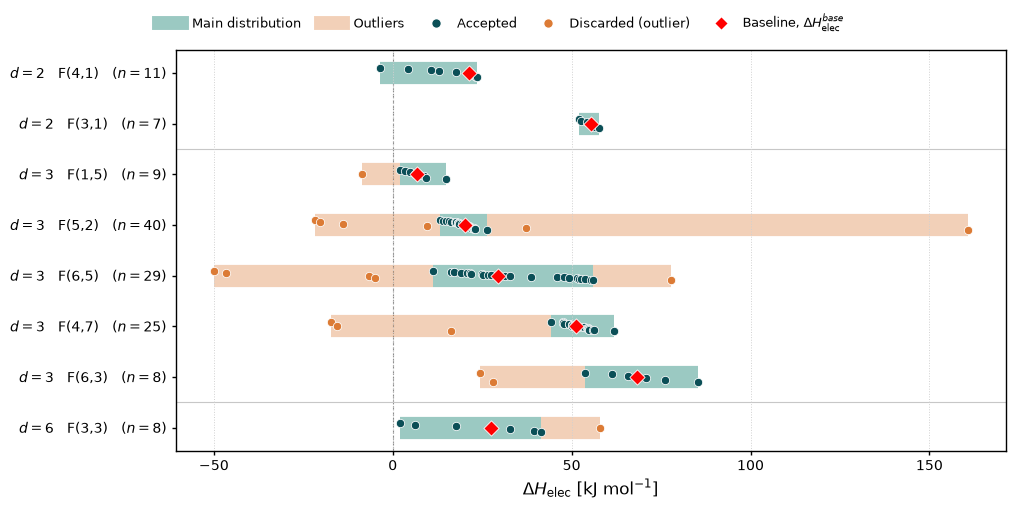

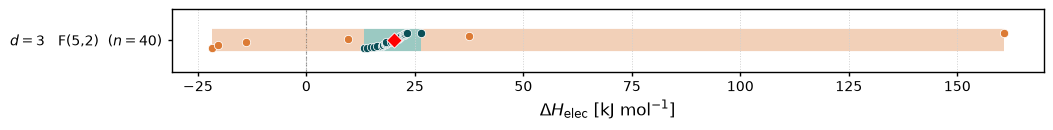

All-family figure saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/dHelec_family_baseline_tunability.png
F(5,2) bpp example saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/dHelec_family_bpp_example.png


In [16]:
baseline_col    = 'dHelec Base [kJ/mol]'
tunability_col  = 'dHelec Width [kJ/mol]'
central_min_col = 'Central Window Min dHelec [kJ/mol]'
central_max_col = 'Central Window Max dHelec [kJ/mol]'

colors = {
    'central_window': '#9bc9c2',
    'central_point': '#0b4f57',
    'outside': '#dc7b35',
}

plot_rows = sorted(family_statistics, key=lambda row: (int(row['Denticity']), row[baseline_col]))

fig, ax = plt.subplots(figsize=(10.5, 5.2))
fig.subplots_adjust(left=0.19, right=0.98, bottom=0.12, top=0.89)
for y, statistics in enumerate(plot_rows):
    denticity = int(statistics['Denticity'])
    family = statistics['Family']
    members = [
        row for row in map_data[denticity]
        if row['family_id'] == family and as_float(row.get('dHelec [kJ/mol]')) is not None
    ]
    draw_family_distribution(ax, y, members, statistics, colors=colors)

ax.set_yticks(
    range(len(plot_rows)),
    [
        rf'$d={int(row["Denticity"])}$   {row["Family"]}   $(n={int(row["Num Analysed Entries"])})$'
        for row in plot_rows
    ],
)
ax.invert_yaxis()
ax.axvline(0, color='0.55', linestyle='--', linewidth=0.8, zorder=0)

for boundary in [
    i + 0.5 for i in range(len(plot_rows) - 1)
    if plot_rows[i]['Denticity'] != plot_rows[i + 1]['Denticity']
]:
    ax.axhline(boundary, color='0.78', linewidth=0.8, zorder=0)

ax.set_xlabel(r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]', fontsize=12)
ax.tick_params(direction='out', length=3, width=1)
ax.grid(axis='x', linestyle=':', color='0.82', linewidth=0.7, zorder=0)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.0)
add_family_legends(fig, colors=colors)

plt.savefig(all_families_path, dpi=400, bbox_inches='tight')
plt.savefig(all_families_pdf, bbox_inches='tight')
plt.show()

# Standalone bpp worked example for the ESI.
example_family = next(row['family_id'] for row in map_data[3] if row['Refcode'] == 'BUTPOY')
example = next(
    row for row in family_statistics
    if int(row['Denticity']) == 3 and row['Family'] == example_family
)
example_members = [
    row for row in map_data[3]
    if row['family_id'] == example_family and as_float(row.get('dHelec [kJ/mol]')) is not None
]

fig, ax = plt.subplots(figsize=(10.5, 2.4))
fig.subplots_adjust(left=0.15, right=0.98, bottom=0.24, top=0.5)
draw_family_distribution(ax, 0, example_members, example, colors=colors)
ax.set_yticks([0], [rf'$d=3$   {example_family}  ($n={int(example["Num Analysed Entries"])}$)'])
ax.set_ylim(-0.36, 0.36)
ax.axvline(0, color='0.55', linestyle='--', linewidth=0.8, zorder=0)
ax.set_xlabel(r'$\Delta H_{\mathrm{elec}}$ [kJ mol$^{-1}$]', fontsize=12)
ax.grid(axis='x', linestyle=':', color='0.82', linewidth=0.7, zorder=0)
ax.tick_params(direction='out', length=3, width=1)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.0)

plt.savefig(example_path, dpi=400, bbox_inches='tight')
plt.savefig(example_pdf, bbox_inches='tight')
plt.show()

print(f'All-family figure saved to: {all_families_path}')
print(f'{example_family} bpp example saved to: {example_path}')


### 5.2 Variance Decomposition by Ligand Family

This complementary analysis tests whether ligand-core identity accounts for a measurable part of the observed $\Delta H_{\mathrm{elec}}$ variation without defining or removing family-level outliers. Families are compared only within their denticity class, and the observed variance is partitioned into between-family and within-family components with an unbalanced nested one-way model. The family intraclass correlation (ICC) estimates the fraction of the within-denticity variance associated with family identity. Its significance is evaluated by shuffling $\Delta H_{\mathrm{elec}}$ values among families within each denticity while retaining the observed family sizes.

Because sparsely represented families provide little information about within-family variation, the calculation is repeated while progressively increasing the minimum family size. Every compound is retained: no Tukey fences, gap threshold, largest-segment selection, or additional structural filtering is applied. Isolated extreme values therefore increase the estimated within-family variance and generally reduce the ICC. At high minimum sizes, the number of retained families must be considered together with the ICC because the analysis ceases to represent the wider ligand-core space.

In [17]:
n_permutations = 5000
random_seed = 7
minimum_family_sizes = range(1, 9)

variance_results = [
    ligand_family_variance_decomposition(
        map_data, minimum_family_size=minimum_family_size,
        n_permutations=n_permutations, random_seed=random_seed,
    )
    for minimum_family_size in minimum_family_sizes
]

write_csv_rows(variance_path, rounded_rows(variance_results, {
    'Between-Family SS Fraction': 4,
    'Between-Family Variance [kJ2/mol2]': 2,
    'Within-Family Variance [kJ2/mol2]': 2,
    'Family ICC': 4,
    'Permutation p-value': 5,
}))

print(f"{'Minimum family size':>19} {'Entries':>8} {'Families':>9} {'SS fraction':>12} {'ICC':>8} {'Permutation p':>14}")
for row in variance_results:
    print(
        f"{row['Minimum Family Size']:>19} {row['Num Entries']:>8} {row['Num Families']:>9} "
        f"{row['Between-Family SS Fraction']:>12.3f} {row['Family ICC']:>8.3f} "
        f"{row['Permutation p-value']:>14.5f}"
    )

print(f'\nVariance decomposition saved to: {variance_path}')

Minimum family size  Entries  Families  SS fraction      ICC  Permutation p
                  1      299        96        0.550    0.368        0.00020
                  2      245        42        0.404    0.323        0.00020
                  3      215        27        0.338    0.295        0.00020
                  4      191        19        0.327    0.320        0.00020
                  5      171        14        0.302    0.321        0.00020
                  6      156        11        0.298    0.342        0.00020
                  7      144         9        0.298    0.365        0.00020
                  8      130         7        0.248    0.308        0.00020
                  9      114         5        0.193    0.241        0.00020
                 10      105         4        0.138    0.188        0.00080

Variance decomposition saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Outputs/ligand_family_dHelec_variance_decompos

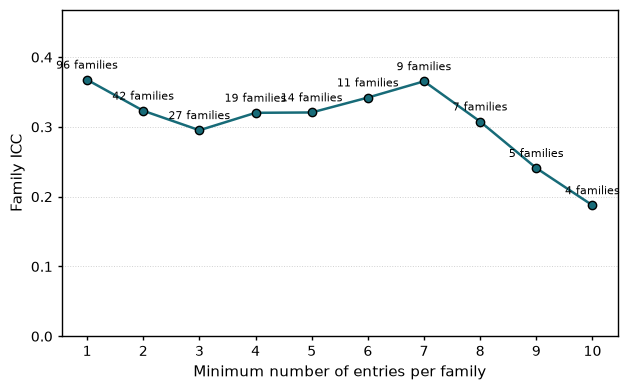

Figure saved to: /Users/sergivela/Documents/SCOPE/Sub-Projects/1-ATLAS/Analysis/1-TMC_Thermodynamics/Figures/dHelec_family_ICC_sensitivity.png


In [18]:
minimum_sizes = [row['Minimum Family Size'] for row in variance_results]
icc_values = [row['Family ICC'] for row in variance_results]

fig, ax = plt.subplots(figsize=(5.4, 3.2), tight_layout=True)
ax.plot(minimum_sizes, icc_values, color='#176b78', marker='o', markeredgecolor='black', linewidth=1.8)

annotation_offsets = {
    1: (8, 10, 'left'), 5: (0, 24, 'center'),
    7: (0, 24, 'center'), 8: (-8, 10, 'right'),
}
for minimum_size, icc, row in zip(minimum_sizes, icc_values, variance_results):
    x_offset, y_offset, alignment = annotation_offsets.get(minimum_size, (0, 10, 'center'))
    ax.annotate(
        f"{row['Num Families']} families", (minimum_size, icc),
        xytext=(x_offset, y_offset), textcoords='offset points', ha=alignment, fontsize=8,
    )

ax.set_xlabel('Minimum number of entries per family', fontsize=11)
ax.set_ylabel(r'$\mathrm{ICC}_{f}$', fontsize=11)
ax.set_xticks(minimum_sizes)
ax.set_ylim(0, max(icc_values) + 0.10)
ax.grid(axis='y', linestyle=':', color='0.82', linewidth=0.7)
ax.tick_params(direction='out', length=3, width=1)
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(1.0)

if icc_figure_path:
    plt.savefig(icc_figure_path, dpi=400, bbox_inches='tight')
plt.show()
if icc_figure_path:
    print(f'Figure saved to: {icc_figure_path}')